## Lab 4: FIR filters and envelopes

The goal of this lab is to connect the FIR filter ideas from the theory summary with the synthesis workflow from the previous labs. We will study two related ideas:

- a finite impulse response (FIR) filter as a weighted sum of past samples, and
- an envelope detector built from a rectifier followed by smoothing.

The theory summary on FIR filters introduces the key concepts behind convolution, impulse response, and the low-pass effect of a moving-average filter. The exercises below are designed to make those ideas concrete in both a toy example and in audio signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from util import load_audio, plot_spectrogram

### 1. FIR filters as weighted sums

An FIR filter computes the output as

$$
y[n] = \sum_{k=0}^{M} b_k x[n-k]
$$

where the coefficients $b_k$ define the filter. In the special case of a moving-average filter, all coefficients are equal to $1/(M+1)$ so the output is the average of $M+1$ input samples. This is exactly the operation implemented by convolution with an impulse response that is a short rectangular pulse.

A useful way to think about this is: the filter output at each instant is a local average of the input, so sharp changes get smoothed. That is why a moving-average filter is often used as a simple low-pass filter.

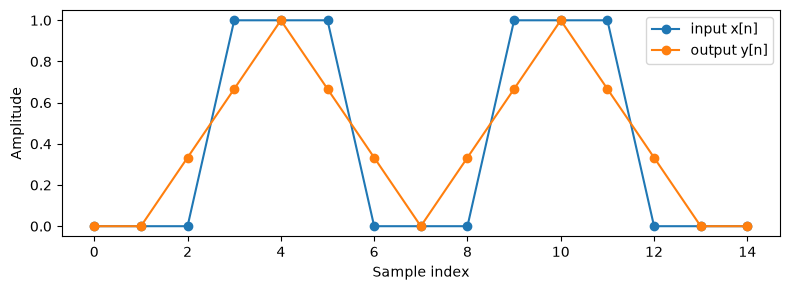

In [ ]:
fs = 1
x = np.array([0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0], dtype=float)
b = np.array([1/3, 1/3, 1/3])
y = np.convolve(b, x, mode='same') #same se queda con la longitud de x

plt.figure(figsize=(8, 3))
plt.plot(x, 'o-', label='input x[n]')
plt.plot(y, 'o-', label='output y[n]')
plt.xlabel('Sample index')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

#### 1.1 Questions

1. Which parts of the signal become smoother after filtering?
    - La subida y la bajada al pico del array.
2. Why does the filtered output change more gradually than the original input?
    - Porque hace un promedio teniendo en cuenta los anteriores, entonces a veces se hace la media de 0s y 1s y da valores mas pequeños.
3. What would happen to the smoothing effect if the filter used more coefficients?
    - Seria aun más suave, porque tienes en cuenta más valores aun (haces la media de más)


#### 1.2 Implement an averaging filter
Complete the function below so that it applies an $N$-point moving-average filter with `np.convolve` and returns a result with the same length as the input. Try different values of $N$.

In [5]:
def averaging_filter(x, N):
    x = np.asarray(x, dtype=float)
    b = np.ones(N) / N
    return np.convolve(x, b, mode='same')

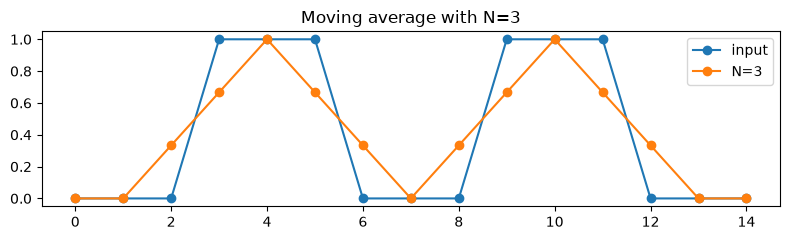

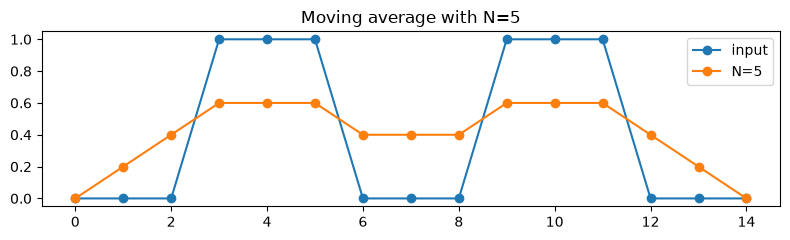

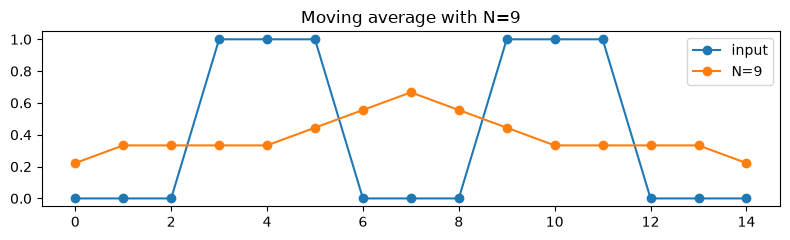

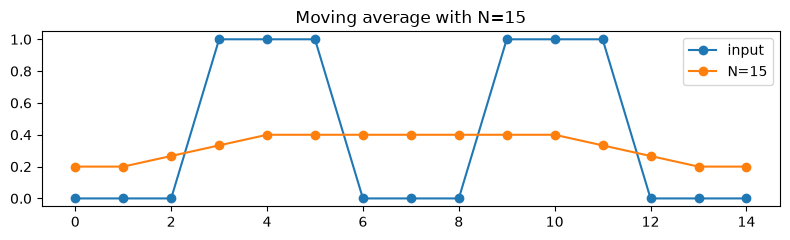

In [10]:
for N in [3, 5, 9, 15]:
    y_N = averaging_filter(x, N)
    plt.figure(figsize=(8, 2.5))
    plt.plot(x, 'o-', label='input')
    plt.plot(y_N, 'o-', label=f'N={N}')
    plt.title(f'Moving average with N={N}')
    plt.legend()
    plt.tight_layout()
    plt.show()

#### 1.3 Questions

1. What happens to the output when $N$ becomes larger?
   - Answer: Se hace cada vez más suave

2. Why does the filter behave like a low-pass filter?
   - Answer: Porque deja pasar las frecuencias bajas y atenua las rápidas, cuando el valor es alto el filtro lo rebaja y si es bajo lo alza un poco.

3. Which frequencies are attenuated more strongly: low frequencies or high frequencies? [note: be careful because we are visualizing time-domain]
   - Answer: Se atenuan las altas frecuencias

### 2. Envelope detection with rectification and smoothing
An detector uses two blocks:
1. a full-wave rectifier, implemented with `np.abs(x)`, and
2. a smoothing filter, implemented with the averaging filter from above.

The rectifier removes the sign of the signal, turning oscillations into a positive waveform. The averaging stage then removes the rapid oscillations and keeps the slower rise and fall of the envelope.

#### 2.1 Add envelope detector
Modify the following functions to try a few different values of $N$ and compare the resulting envelope.

In [11]:
def envelope(x, N):
    x = np.asarray(x, dtype=float)
    rectified = np.abs(x)
    return averaging_filter(rectified, N)

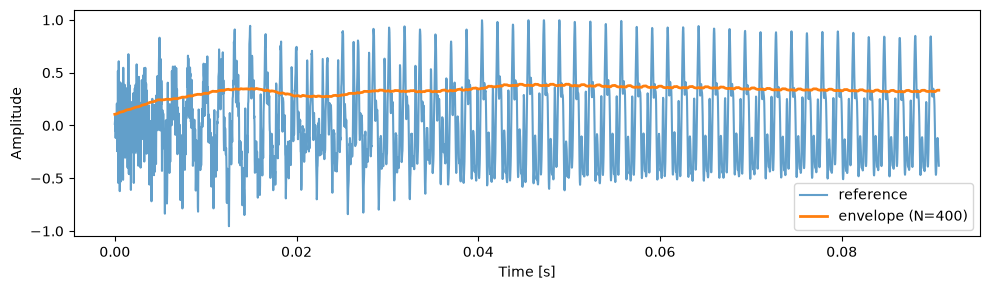

In [39]:
reference_audio, fs = load_audio('../audio_elegido/celtic_harp_D5.wav')
t = np.arange(len(reference_audio)) / fs

N = 400
env = envelope(reference_audio, N)

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], reference_audio[:4000], alpha=0.7, label='reference')
plt.plot(t[:4000], env[:4000], linewidth=2, label=f'envelope (N={N})')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

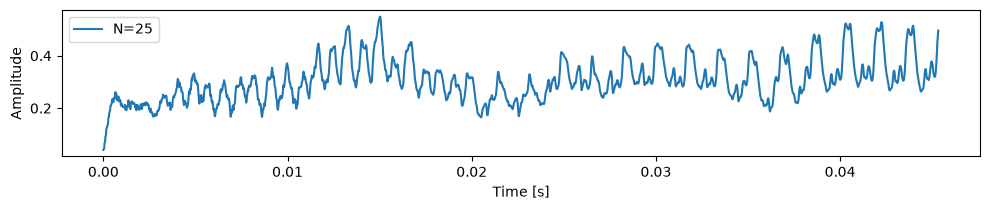

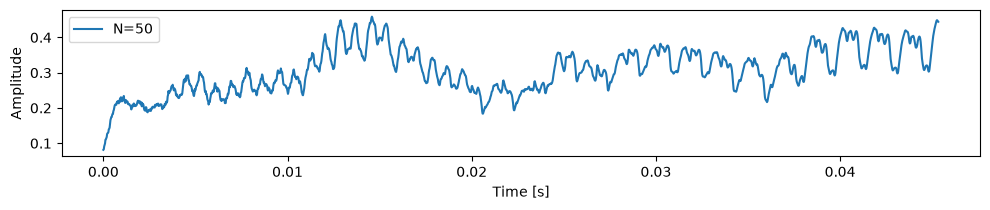

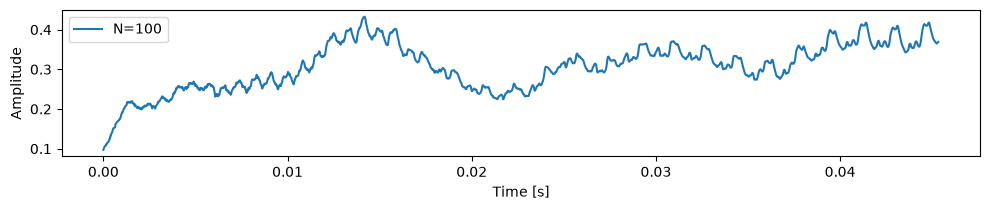

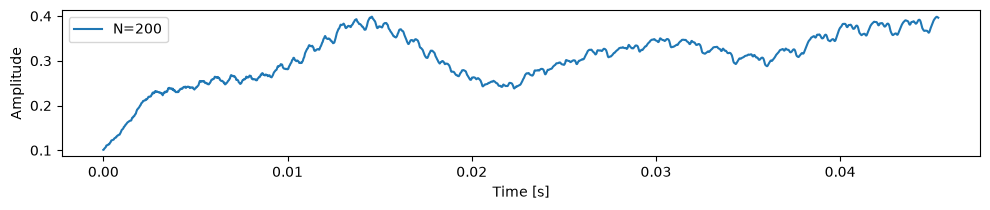

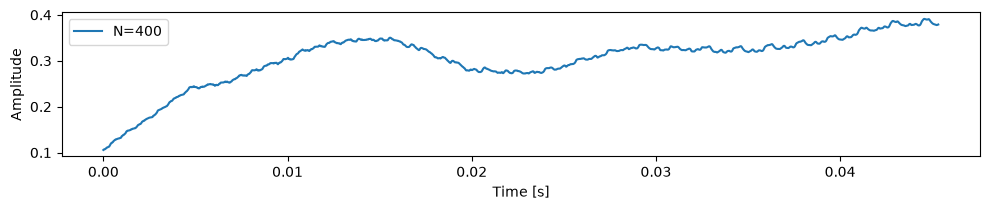

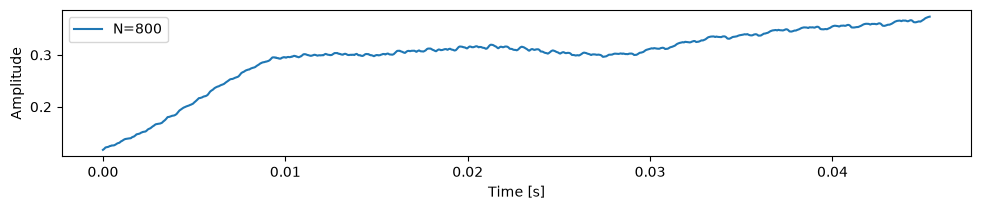

In [23]:
# Try a few filter sizes and inspect how the envelope changes
for N in [25,50,100, 200, 400,800]:
    env_N = envelope(reference_audio, N)
    plt.figure(figsize=(10, 2.2))
    plt.plot(t[:2000], env_N[:2000], label=f'N={N}')
    plt.xlabel('Time [s]')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Try adding one or two more values of N here to see how the smoothing changes
# for example: [25, 100, 400, 1600]


#### 2.2 Questions

1. Why does the rectifier make the envelope easier to estimate?
   - Answer: Para que no se compensen y de 0 la media.

2. What happens if $N$ is very small?
   - Answer: Pasa lo que hemos visto antes, no coge muchas muestras y no es tan suave

3. What happens if $N$ is very large?
   - Answer: Coge muchas mas muestras y sale un 'envelope' más suave

### 3. Apply the envelope to a synthesized sound

Now we combine the harmonic synthesis idea from Lab 3 with the envelope detector from this lab. The goal is to make the synthesized signal look and sound more like the reference by multiplying the harmonic signal by a slowly varying envelope. Add the amplitude weights obtained in Lab 3.

#### 3.1 Add envelope

Add your own amplitude weights in the code cell below and try at least two different values of the smoothing window $N$.
You can compare how the synthesized sound changes when the envelope is smoother or less smooth.


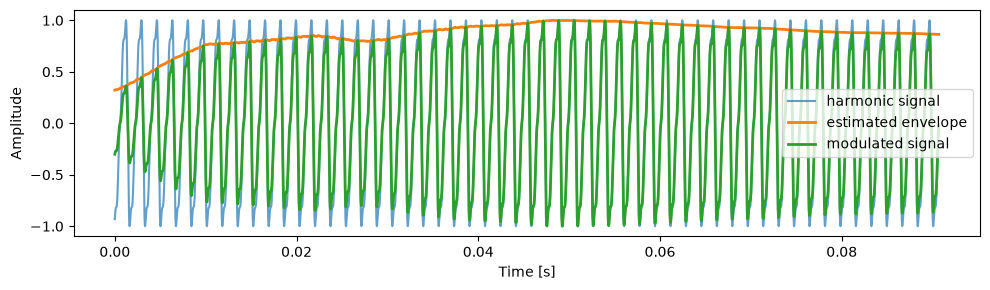

In [45]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

f0 = 588
phi = 2.578141307339463
# add your own amplitude weights
weights = [1.0, 0.2818382931264453, 0.12589254117941667, 0.1412537544622754, 0.0028183829312644535, 0.003548133892335755] 
t = np.arange(len(reference_audio)) / fs

harmonic_signal = synthesize(f0, phi, weights, t)
harmonic_signal = harmonic_signal / np.max(np.abs(harmonic_signal))

# try different values of N
N = 901
envelope_signal = envelope(reference_audio, N)
envelope_signal = envelope_signal / np.max(np.abs(envelope_signal))

modulated_signal = harmonic_signal * envelope_signal
modulated_signal = modulated_signal / np.max(np.abs(modulated_signal))

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], harmonic_signal[:4000], alpha=0.7, label='harmonic signal')
plt.plot(t[:4000], envelope_signal[:4000], linewidth=2, label='estimated envelope')
plt.plot(t[:4000], modulated_signal[:4000], linewidth=2, label='modulated signal')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

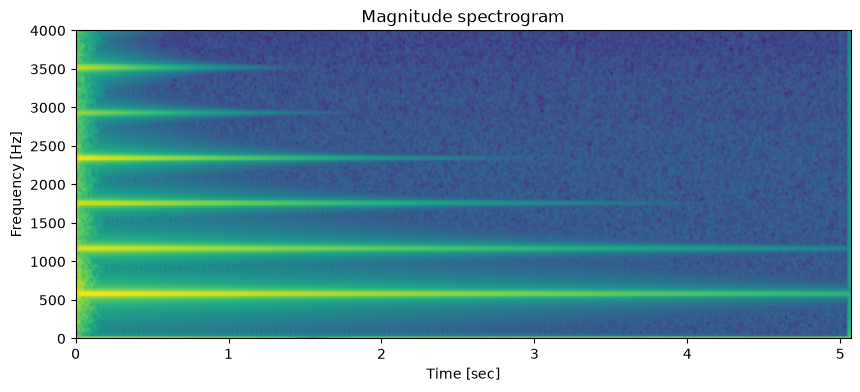

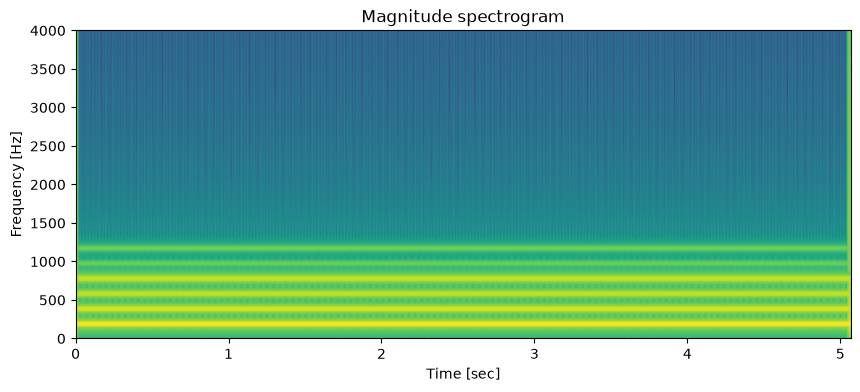

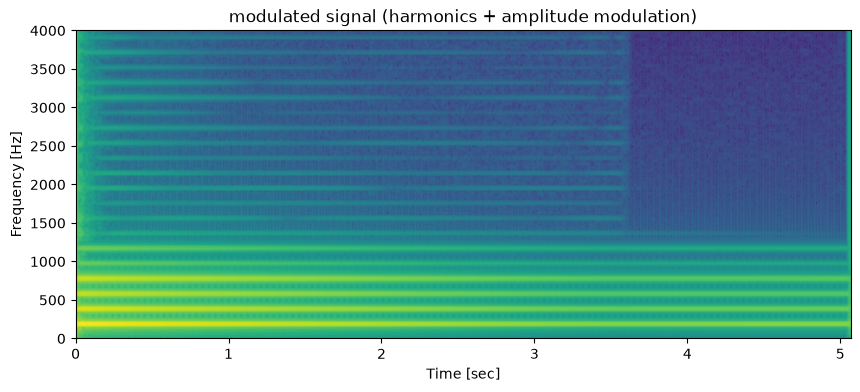

In [37]:
# The envelope introduces amplitude modulation, so the modulated signal will show more structure than a pure harmonic tone.
ax1 = plot_spectrogram(reference_audio, sr=fs, N=2048, H=256)
ax2 = plot_spectrogram(harmonic_signal, sr=fs, N=2048, H=256)
ax3 = plot_spectrogram(modulated_signal, sr=fs, N=2048, H=256)

ax1.set_ylim([0, 4000])
ax2.set_ylim([0, 4000])
ax3.set_ylim([0, 4000])
ax3.set_title('modulated signal (harmonics + amplitude modulation)')
plt.show()


In [38]:
from IPython.display import Audio, display

print("Reference sound")
display(Audio(reference_audio, rate=fs))

print("Harmonic sound")
display(Audio(harmonic_signal, rate=fs))

print("Modulated sound")
display(Audio(modulated_signal, rate=fs))


Reference sound


Harmonic sound


Modulated sound


#### 3.2 Questions

1. How does the envelope change the amplitude of the sound over time?
   - Answer: La envolvente ajusta la magnitud instantanea de la onda, controlando aspectos como la velocidad de ataque, el sostenido y el decaimiento.

2. What is the main difference between the spectrogram of the pure harmonic signal and the spectrogram of the modulated signal?
   - Answer: El pure harmonic solo deja ver las frecuencias bajas, y la modulada deja ver frecuencias altas tambien (aunque con menos fuerza que el original)

3. Why does the modulated signal show more structure than the purely harmonic signal?
   - Answer: Porque incorpora la dinámica temporal del sonido original sobre el espectro armónico. La señal armónica pura es estacionaria y uniforme a lo largo del tiempo, la modulacion introduce cambios de energia.

4. Why is the smoothing stage important for creating a realistic amplitude envelope?
   - Answer: Sin el suavizado, la envolvente contendria rizado continuo y transiciones abruptas que producirian distorsion o chasquidos auditivos al modular la señal